In [ ]:
##cell 0
import os
import pandas as pd
from sklearn.preprocessing import StandardScaler

print("Loading KDD Cup 2015 log data...")
log_train = pd.read_csv("data/raw/train/train/log_train.csv")
log_train['time'] = pd.to_datetime(log_train['time'])
log_train = log_train.sort_values(['enrollment_id', 'time'])

def extract_and_scale_events(df, output_dir=None):
    """Pivots raw event logs into student feature counts and applies StandardScaler."""
    counts = df.groupby(['enrollment_id', 'event']).size().unstack(fill_value=0)
    counts.columns = [f'event_{col}' for col in counts.columns]
    counts = counts.reset_index()
    
    feat_cols = [c for c in counts.columns if c != 'enrollment_id']
    scaler = StandardScaler()
    counts_scaled = counts.copy()
    counts_scaled[feat_cols] = scaler.fit_transform(counts[feat_cols])
    
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
        counts.to_csv(os.path.join(output_dir, "raw_counts.csv"), index=False)
        counts_scaled.to_csv(os.path.join(output_dir, "norm.csv"), index=False)
        
    return counts_scaled

print("Calculating temporal slice masks...")
first_time = log_train.groupby('enrollment_id')['time'].transform('min')
last_time = log_train.groupby('enrollment_id')['time'].transform('max')

w1_mask = (log_train['time'] - first_time).dt.total_seconds() <= 7 * 24 * 3600
last_mask = (last_time - log_train['time']).dt.total_seconds() <= 7 * 24 * 3600

slices = {
    "full": log_train,
    "w1": log_train[w1_mask],
    "last": log_train[last_mask]
}

# Output directories
RAW_OUTPUT_DIR = "data/temporal_event_counts"
PROP_OUTPUT_DIR = "data/temporal_event_proportions"

os.makedirs(RAW_OUTPUT_DIR, exist_ok=True)
os.makedirs(PROP_OUTPUT_DIR, exist_ok=True)

master_cols = None

for name, subset in slices.items():
    print(f"Processing {name} temporal slice...")
    df_slice = subset.groupby(['enrollment_id', 'event']).size().unstack(fill_value=0)
    df_slice.columns = [f'event_{col}' for col in df_slice.columns]
    df_slice = df_slice.reset_index()
    
    if master_cols is None:
        master_cols = df_slice.columns
    else:
        df_slice = df_slice.reindex(columns=master_cols, fill_value=0)
        
    feat_cols = [c for c in master_cols if c != 'enrollment_id']

# ============================================================
# 1. RAW COUNT REPRESENTATION
# ============================================================

    raw_counts = df_slice.copy()

    raw_out_path = f"{RAW_OUTPUT_DIR}/{name}_norm.csv"

    scaler_raw = StandardScaler()
    raw_scaled = raw_counts.copy()
    raw_scaled[feat_cols] = scaler_raw.fit_transform(raw_counts[feat_cols])

    raw_scaled.to_csv(raw_out_path, index=False)

    print(f"Saved RAW {name} shape: {raw_scaled.shape} to {raw_out_path}")


# ============================================================
# 2. PROPORTIONAL REPRESENTATION
# ============================================================

    proportions = df_slice.copy()

    # Total number of events for each student
    row_totals = proportions[feat_cols].sum(axis=1)

    # Convert each event count into its proportion of total activity
    proportions[feat_cols] = proportions[feat_cols].div(
        row_totals.replace(0, 1),
        axis=0
    )

    # Save the unscaled proportions
    prop_raw_path = f"{PROP_OUTPUT_DIR}/{name}_proportions.csv"
    proportions.to_csv(prop_raw_path, index=False)

    # Standardize the proportional features for clustering
    scaler_prop = StandardScaler()
    prop_scaled = proportions.copy()
    prop_scaled[feat_cols] = scaler_prop.fit_transform(proportions[feat_cols])

    # Save standardized proportions
    prop_norm_path = f"{PROP_OUTPUT_DIR}/{name}_norm.csv"
    prop_scaled.to_csv(prop_norm_path, index=False)

    print(f"Saved PROPORTIONS {name} shape: {prop_scaled.shape} to {prop_norm_path}")

Loading KDD Cup 2015 log data...
Calculating temporal slice masks...
Processing full temporal slice...
Saved full shape: (120542, 8) to data/temporal_event_counts/full_norm.csv
Processing w1 temporal slice...
Saved w1 shape: (120542, 8) to data/temporal_event_counts/w1_norm.csv
Processing last temporal slice...
Saved last shape: (120542, 8) to data/temporal_event_counts/last_norm.csv


Executing acceleration on: cuda

--- INPUT DIMENSION: FULL ---
Silhouette: 0.795 | Davies-Bouldin: 0.819 | Calinski-Harabasz: 47562.2

Average Raw Event Counts per Cluster (for Manual Labeling):
         event_video  event_access  event_wiki  event_discussion
cluster                                                         
0               3.46         14.72        0.45              2.29
1              45.11        160.88        4.26             38.88
2              93.18        502.09       97.86           1881.55


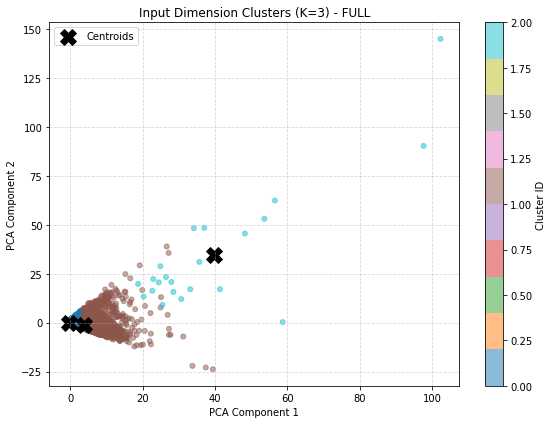


--- INPUT DIMENSION: W1 ---
Silhouette: 0.732 | Davies-Bouldin: 0.928 | Calinski-Harabasz: 39111.3

Average Raw Event Counts per Cluster (for Manual Labeling):
         event_video  event_access  event_wiki  event_discussion
cluster                                                         
0               1.98          8.52        0.33              1.44
1              20.27         68.14        1.74             17.13
2              11.22         54.58       29.61             94.98


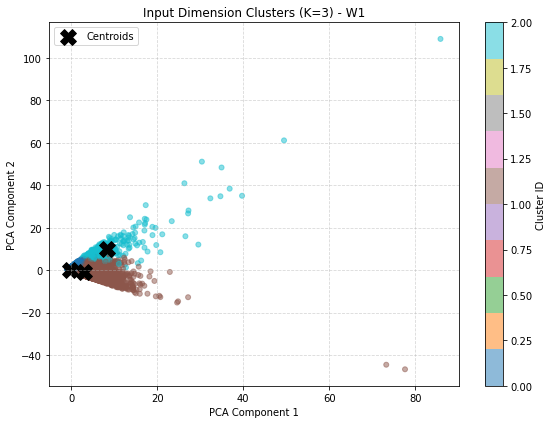


--- INPUT DIMENSION: LAST ---
Silhouette: 0.758 | Davies-Bouldin: 0.852 | Calinski-Harabasz: 38048.0

Average Raw Event Counts per Cluster (for Manual Labeling):
         event_video  event_access  event_wiki  event_discussion
cluster                                                         
0               1.96          8.33        0.24              0.99
1              11.88         49.87       33.94             82.49
2              22.26         71.67        0.92             12.32


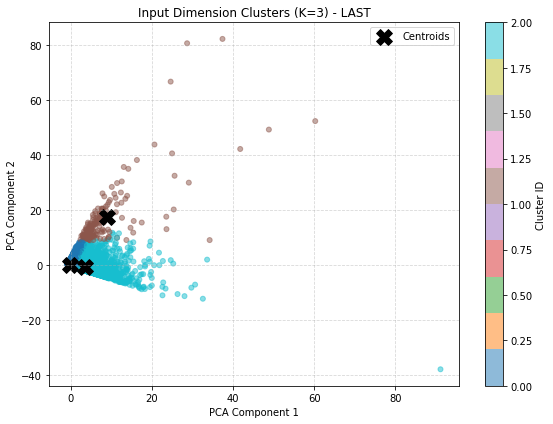

In [ ]:
##cell 1
import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Set up NVIDIA A40 GPU device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing acceleration on: {device}")

input_cols = ['event_video', 'event_access', 'event_wiki', 'event_discussion']
slices = ['full', 'w1', 'last']

# Choose which representation to cluster
REPRESENTATION = "raw"

if REPRESENTATION == "raw":
    FEATURE_DIR = "data/temporal_event_counts"
elif REPRESENTATION == "proportional":
    FEATURE_DIR = "data/temporal_event_proportions"
else:
    raise ValueError("REPRESENTATION must be 'raw' or 'proportional'")

# Load raw logs once to dynamically compute unscaled raw event counts per temporal slice
log_train = pd.read_csv("data/raw/train/train/log_train.csv")
log_train['time'] = pd.to_datetime(log_train['time'])
log_train = log_train.sort_values(['enrollment_id', 'time'])

first_time = log_train.groupby('enrollment_id')['time'].transform('min')
last_time = log_train.groupby('enrollment_id')['time'].transform('max')

w1_mask = (log_train['time'] - first_time).dt.total_seconds() <= 7 * 24 * 3600
last_mask = (last_time - log_train['time']).dt.total_seconds() <= 7 * 24 * 3600

slice_dataframes = {
    'full': log_train,
    'w1': log_train[w1_mask],
    'last': log_train[last_mask]
}

for slice_name in slices:
    norm_path = f"{FEATURE_DIR}/{slice_name}_norm.csv"
    if not os.path.exists(norm_path):
        continue
        
    df_norm = pd.read_csv(norm_path)
    
    # Isolate input columns and push to A40 GPU memory as PyTorch tensors
    cols_to_use = [c for c in input_cols if c in df_norm.columns]
    X_np = df_norm[cols_to_use].values
    X_tensor = torch.tensor(X_np, dtype=torch.float32, device=device)
    
    # Run K-Means (K=3)
    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    clusters = kmeans.fit_predict(X_np)
    
    df_norm['cluster'] = clusters
    
    # Calculate evaluation metrics
    sil = silhouette_score(X_np, clusters)
    db = davies_bouldin_score(X_np, clusters)
    ch = calinski_harabasz_score(X_np, clusters)
    
    print(f"\n==================================================")
    print(f"--- INPUT DIMENSION: {slice_name.upper()} ---")
    print(f"==================================================")
    print(f"Silhouette: {sil:.3f} | Davies-Bouldin: {db:.3f} | Calinski-Harabasz: {ch:.1f}")
    
    # Compute average raw event counts per cluster for manual identification
    subset_df = slice_dataframes[slice_name]
    raw_counts = subset_df.groupby(['enrollment_id', 'event']).size().unstack(fill_value=0)
    raw_counts.columns = [f'event_{col}' for col in raw_counts.columns]
    raw_counts = raw_counts.reset_index()
    
    merged_raw = df_norm[['enrollment_id', 'cluster']].merge(raw_counts, on='enrollment_id', how='left').fillna(0)
    raw_cols_to_use = [c for c in input_cols if c in merged_raw.columns]
    raw_means = merged_raw.groupby('cluster')[raw_cols_to_use].mean()
    
    print("\nAverage Raw Event Counts per Cluster (for Manual Labeling):")
    print(raw_means.round(2).to_string())
    
    # PCA for fast 2D projection and visualization
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_np)
    df_norm['pca1'] = X_pca[:, 0]
    df_norm['pca2'] = X_pca[:, 1]
    
    pca_centroids = pca.transform(kmeans.cluster_centers_)
    
    # Plotting using pure Matplotlib
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(
        df_norm['pca1'], df_norm['pca2'], 
        c=df_norm['cluster'], 
        cmap='tab10', 
        alpha=0.5, 
        s=25
    )
    plt.scatter(
        pca_centroids[:, 0], pca_centroids[:, 1], 
        s=250, c='black', marker='X', label='Centroids'
    )
    plt.title(f'Input Dimension Clusters (K=3) - {slice_name.upper()}')
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.colorbar(scatter, label='Cluster ID')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

In [ ]:
##cell 2
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

print("--- Cluster Alignment Analysis ---")

input_cols = ['event_video', 'event_access', 'event_wiki', 'event_discussion']
slices = ['full', 'w1', 'last']

for slice_name in slices:
    # Load normalized data
    norm_path = f"{FEATURE_DIR}/{slice_name}_norm.csv"
    df_norm = pd.read_csv(norm_path)
    
    # Re-run K-Means quickly to ensure the 'cluster' column is mapped to this exact slice
    cols_to_use = [c for c in input_cols if c in df_norm.columns]
    X_np = df_norm[cols_to_use].values
    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    df_norm['cluster'] = kmeans.fit_predict(X_np)
    
    # Extract raw counts for this slice using 'slice_dataframes' already in memory from Cell 2
    subset_df = slice_dataframes[slice_name]
    raw_counts = subset_df.groupby(['enrollment_id', 'event']).size().unstack(fill_value=0)
    raw_counts.columns = [f'event_{col}' for col in raw_counts.columns]
    
    # Merge the raw counts with the cluster assignments
    merged_raw = df_norm[['enrollment_id', 'cluster']].merge(raw_counts, on='enrollment_id', how='left').fillna(0)
    
    # 1. Calculate Scores strictly following the FSLSM table
    # We use .get() to prevent KeyError if a specific event type didn't happen in that timeframe
    visual_score = merged_raw.get('event_video', 0) + merged_raw.get('event_access', 0)
    verbal_score = merged_raw.get('event_access', 0) + merged_raw.get('event_wiki', 0) + merged_raw.get('event_discussion', 0)
    
    df_norm['visual_score'] = visual_score
    df_norm['verbal_score'] = verbal_score
    
    # 2. Assign True Labels (Vectorized)
    conditions = [
        df_norm['visual_score'] > df_norm['verbal_score'],
        df_norm['verbal_score'] > df_norm['visual_score']
    ]
    df_norm['true_label'] = np.select(conditions, ['Visual', 'Verbal'], default='Neutral')
    
    # 3. Cluster Analysis: Cross-tabulate Clusters with True Labels
    print(f"\n=== {slice_name.upper()} SLICE ===")
    alignment = pd.crosstab(df_norm['cluster'], df_norm['true_label'], normalize='index') * 100
    print(alignment.round(2).to_string())

--- Cluster Alignment Analysis ---

=== FULL SLICE ===
true_label  Neutral  Verbal  Visual
cluster                            
0             36.83   17.62   45.55
1              0.67   32.11   67.22
2              0.00  100.00    0.00

=== W1 SLICE ===
true_label  Neutral  Verbal  Visual
cluster                            
0             40.09   17.84   42.07
1              1.20   32.68   66.12
2              0.00   98.92    1.08

=== LAST SLICE ===
true_label  Neutral  Verbal  Visual
cluster                            
0             42.26   14.26   43.48
1              0.63   98.11    1.26
2              1.05   20.97   77.98


Running DEC on: cuda

--- INPUT DIMENSION: FULL (DEC) ---
    epoch   0 | loss: 0.04071 | label change: 0.0007
    epoch  20 | loss: 0.04380 | label change: 0.0008
    epoch  40 | loss: 0.04563 | label change: 0.0008
    epoch  60 | loss: 0.04671 | label change: 0.0006
    epoch  80 | loss: 0.04727 | label change: 0.0002
    converged at epoch 82 (label change < 0.0001)
Silhouette: 0.745 | Davies-Bouldin: 0.855 | Calinski-Harabasz: 44635.0

Average Raw Event Counts per DEC Cluster (for Manual Labeling):
             event_video  event_access  event_wiki  event_discussion
dec_cluster                                                         
0                   2.49         10.91        0.37              1.67
1                  34.05        124.81        3.16             27.58
2                  92.09        486.30      104.04           1802.13


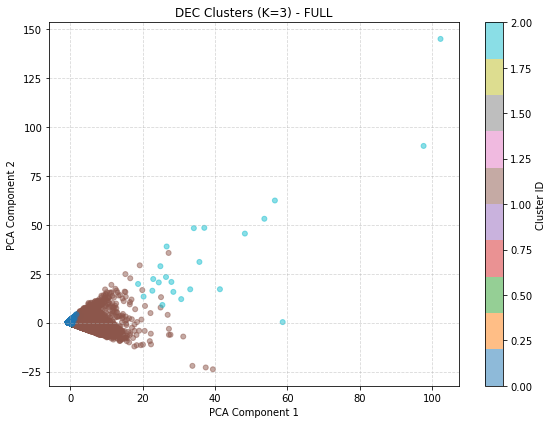


--- INPUT DIMENSION: W1 (DEC) ---
    epoch   0 | loss: 0.04739 | label change: 0.0010
    epoch  20 | loss: 0.05198 | label change: 0.0014
    epoch  40 | loss: 0.05467 | label change: 0.0011
    epoch  60 | loss: 0.05594 | label change: 0.0003
    converged at epoch 69 (label change < 0.0001)
Silhouette: 0.668 | Davies-Bouldin: 0.980 | Calinski-Harabasz: 36915.3

Average Raw Event Counts per DEC Cluster (for Manual Labeling):
             event_video  event_access  event_wiki  event_discussion
dec_cluster                                                         
0                   1.40          6.42        0.26              1.05
1                  15.01         51.76        1.42             11.82
2                  12.90         68.95       26.84             93.87


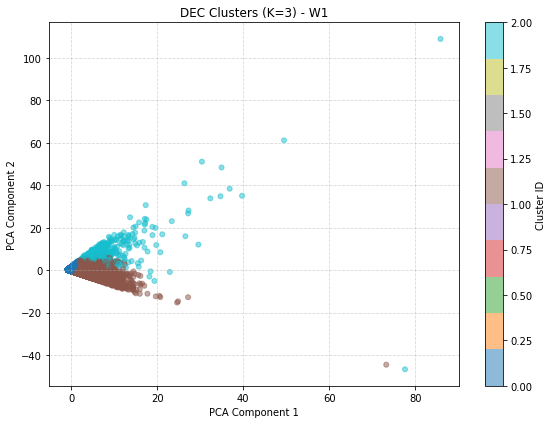


--- INPUT DIMENSION: LAST (DEC) ---
    epoch   0 | loss: 0.04236 | label change: 0.0009
    epoch  20 | loss: 0.04636 | label change: 0.0011
    epoch  40 | loss: 0.04893 | label change: 0.0010
    epoch  60 | loss: 0.05065 | label change: 0.0008
    epoch  80 | loss: 0.05172 | label change: 0.0006
    converged at epoch 91 (label change < 0.0001)
Silhouette: 0.682 | Davies-Bouldin: 0.913 | Calinski-Harabasz: 35211.8

Average Raw Event Counts per DEC Cluster (for Manual Labeling):
             event_video  event_access  event_wiki  event_discussion
dec_cluster                                                         
0                   1.34          6.17        0.20              0.76
1                  12.67         52.48       32.48             79.14
2                  15.44         51.69        0.80              7.84


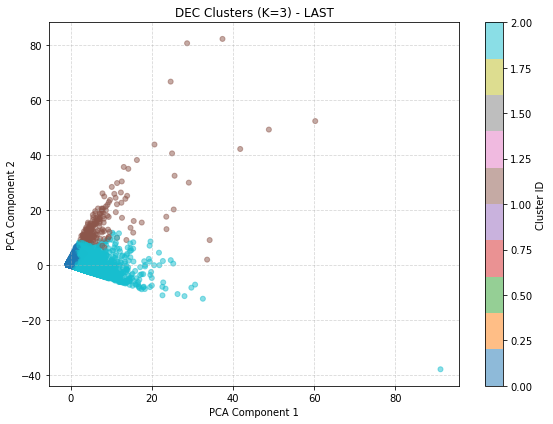

In [ ]:
# =====================================================================
# DEC (Deep Embedded Clustering) — Input Dimension, per temporal slice
#
# Consistent with the earlier decision to skip Autoencoders / any other
# latent representation: this runs DEC's self-training clustering
# refinement directly on the SAME normalized feature space K-Means uses
# (no encoder network, no dimensionality reduction), so the two methods
# are compared on identical input. Cluster centers are initialized from
# K-Means, then refined by minimizing KL divergence between the soft
# (Student's t) assignments and a self-derived sharpened target
# distribution — the core DEC mechanism, without the embedding step.
# =====================================================================
##cell 3
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score


def target_distribution(q):
    weight = q ** 2 / q.sum(0)
    return (weight.t() / weight.sum(1)).t()


class DECClusteringLayer(nn.Module):
    """Clustering layer only — no encoder. Cluster centers are the
    only learnable parameters, refined directly in the input space."""
    def __init__(self, n_clusters, init_centers, alpha=1.0):
        super().__init__()
        self.alpha = alpha
        self.centers = nn.Parameter(torch.tensor(init_centers, dtype=torch.float32))

    def forward(self, x):
        dist_sq = torch.sum((x.unsqueeze(1) - self.centers.unsqueeze(0)) ** 2, dim=2)
        q = 1.0 / (1.0 + dist_sq / self.alpha)
        q = q ** ((self.alpha + 1.0) / 2.0)
        q = q / torch.sum(q, dim=1, keepdim=True)
        return q


def run_dec(X_np, n_clusters=3, n_epochs=100, lr=0.01, tol=1e-4, device="cpu"):
    kmeans_init = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    init_pred = kmeans_init.fit_predict(X_np)
    init_centers = kmeans_init.cluster_centers_

    X_tensor = torch.tensor(X_np, dtype=torch.float32, device=device)
    model = DECClusteringLayer(n_clusters, init_centers).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    prev_labels = init_pred
    for epoch in range(n_epochs):
        q = model(X_tensor)
        p = target_distribution(q.detach())

        loss = torch.nn.functional.kl_div(q.log(), p, reduction='batchmean')
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        with torch.no_grad():
            new_labels = torch.argmax(model(X_tensor), dim=1).cpu().numpy()

        changed = np.sum(new_labels != prev_labels) / len(prev_labels)
        if epoch % 20 == 0:
            print(f"    epoch {epoch:>3} | loss: {loss.item():.5f} | label change: {changed:.4f}")
        if changed < tol and epoch > 0:
            print(f"    converged at epoch {epoch} (label change < {tol})")
            break
        prev_labels = new_labels

    with torch.no_grad():
        final_labels = torch.argmax(model(X_tensor), dim=1).cpu().numpy()

    return final_labels


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running DEC on: {device}\n")

input_cols = ['event_video', 'event_access', 'event_wiki', 'event_discussion']
slices = ['full', 'w1', 'last']

REPRESENTATION = "raw"

if REPRESENTATION == "raw":
    FEATURE_DIR = "data/temporal_event_counts"
elif REPRESENTATION == "proportional":
    FEATURE_DIR = "data/temporal_event_proportions"
else:
    raise ValueError("REPRESENTATION must be 'raw' or 'proportional'")

for slice_name in slices:
    norm_path = f"{FEATURE_DIR}/{slice_name}_norm.csv"
    df_norm = pd.read_csv(norm_path)

    cols_to_use = [c for c in input_cols if c in df_norm.columns]
    X_np = df_norm[cols_to_use].values

    print(f"==================================================")
    print(f"--- INPUT DIMENSION: {slice_name.upper()} (DEC) ---")
    print(f"==================================================")

    dec_labels = run_dec(X_np, n_clusters=3, device=device)
    df_norm['dec_cluster'] = dec_labels

    sil = silhouette_score(X_np, dec_labels)
    db = davies_bouldin_score(X_np, dec_labels)
    ch = calinski_harabasz_score(X_np, dec_labels)
    print(f"Silhouette: {sil:.3f} | Davies-Bouldin: {db:.3f} | Calinski-Harabasz: {ch:.1f}")

    # Average raw event counts per DEC cluster, for manual labeling — mirrors the K-Means cell
    subset_df = slice_dataframes[slice_name]
    raw_counts = subset_df.groupby(['enrollment_id', 'event']).size().unstack(fill_value=0)
    raw_counts.columns = [f'event_{col}' for col in raw_counts.columns]
    raw_counts = raw_counts.reset_index()

    merged_raw = df_norm[['enrollment_id', 'dec_cluster']].merge(raw_counts, on='enrollment_id', how='left').fillna(0)
    raw_cols_to_use = [c for c in input_cols if c in merged_raw.columns]
    raw_means = merged_raw.groupby('dec_cluster')[raw_cols_to_use].mean()

    print("\nAverage Raw Event Counts per DEC Cluster (for Manual Labeling):")
    print(raw_means.round(2).to_string())

    # PCA 2D projection for visualization — mirrors the K-Means cell's plot
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_np)

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dec_labels, cmap='tab10', alpha=0.5, s=25)
    plt.title(f'DEC Clusters (K=3) - {slice_name.upper()}')
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.colorbar(scatter, label='Cluster ID')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    print()

In [ ]:
# =====================================================================
# Binary Visual-Verbal Scoring -> Cluster-Level Labeling (K-Means & DEC)
#
# Per-learner binary score is computed on RAW (unscaled) event counts,
# since V, R, and S are only meaningful as actual counts/ratios, not
# standardized features. Clusters are then labeled Visual/Verbal if a
# clear majority of their members share that binary label, otherwise
# Intermediate.
# =====================================================================
#cell 4
import numpy as np
import pandas as pd
import torch
from sklearn.cluster import KMeans

MAJORITY_THRESHOLD = 0.60  # tune this: min. % of a cluster sharing a
                            # binary label before it's called that style
                            # rather than "Intermediate"


def compute_binary_visual_verbal(raw_counts_df):
    """V, R, S per learner from raw event counts. Ties (V == R, including
    V == R == 0) resolve to Verbal, per the spec's tie-break rule."""
    df = raw_counts_df.copy()
    df['V'] = df.get('event_video', 0) + df.get('event_access', 0)
    df['R'] = df.get('event_wiki', 0) + df.get('event_discussion', 0)
    total = df['V'] + df['R']
    df['S'] = np.where(total > 0, (df['V'] - df['R']) / total, 0.0)
    df['binary_label'] = np.where(df['V'] > df['R'], 'Visual', 'Verbal')
    return df


def summarize_cluster_styles(df_with_cluster, cluster_col, majority_threshold=MAJORITY_THRESHOLD):
    summary = df_with_cluster.groupby(cluster_col).agg(
        n_learners=('binary_label', 'size'),
        avg_V=('V', 'mean'),
        avg_R=('R', 'mean'),
        avg_S=('S', 'mean'),
        pct_visual=('binary_label', lambda x: (x == 'Visual').mean() * 100),
        pct_verbal=('binary_label', lambda x: (x == 'Verbal').mean() * 100),
    )

    def assign_style(row):
        if row['pct_visual'] >= majority_threshold * 100:
            return 'Visual'
        elif row['pct_verbal'] >= majority_threshold * 100:
            return 'Verbal'
        return 'Intermediate'

    summary['cluster_style'] = summary.apply(assign_style, axis=1)
    return summary.round(3)


input_cols = ['event_video', 'event_access', 'event_wiki', 'event_discussion']

REPRESENTATION = "raw"

if REPRESENTATION == "raw":
    FEATURE_DIR = "data/temporal_event_counts"
elif REPRESENTATION == "proportional":
    FEATURE_DIR = "data/temporal_event_proportions"
else:
    raise ValueError("REPRESENTATION must be 'raw' or 'proportional'")

for slice_name in slices:  # 'slices' and 'slice_dataframes' already defined above
    print(f"\n{'=' * 60}")
    print(f"--- {slice_name.upper()}: BINARY VISUAL-VERBAL CLUSTER LABELING ---")
    print(f"{'=' * 60}")

    norm_path = f"{FEATURE_DIR}/{slice_name}_norm.csv"
    df_norm = pd.read_csv(norm_path)
    cols_to_use = [c for c in input_cols if c in df_norm.columns]
    X_np = df_norm[cols_to_use].values

    # Raw (unscaled) counts -- needed for V/R/S, which must use real counts
    subset_df = slice_dataframes[slice_name]
    raw_counts = subset_df.groupby(['enrollment_id', 'event']).size().unstack(fill_value=0)
    raw_counts.columns = [f'event_{col}' for col in raw_counts.columns]
    raw_counts = raw_counts.reset_index()

    # --- K-Means: same random_state as earlier -> identical cluster assignments ---
    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    km_clusters = kmeans.fit_predict(X_np)

    df_km = df_norm[['enrollment_id']].copy()
    df_km['cluster'] = km_clusters
    df_km = df_km.merge(raw_counts, on='enrollment_id', how='left').fillna(0)
    df_km = compute_binary_visual_verbal(df_km)

    km_summary = summarize_cluster_styles(df_km, 'cluster')
    print("\n[K-Means] Cluster-level Visual/Verbal/Intermediate labeling:")
    print(km_summary.to_string())

    # --- DEC: reuses run_dec() defined in the DEC cell above; seeded for reproducibility ---
    torch.manual_seed(42)
    dec_labels = run_dec(X_np, n_clusters=3, device=device)

    df_dec = df_norm[['enrollment_id']].copy()
    df_dec['dec_cluster'] = dec_labels
    df_dec = df_dec.merge(raw_counts, on='enrollment_id', how='left').fillna(0)
    df_dec = compute_binary_visual_verbal(df_dec)

    dec_summary = summarize_cluster_styles(df_dec, 'dec_cluster')
    print("\n[DEC] Cluster-level Visual/Verbal/Intermediate labeling:")
    print(dec_summary.to_string())


--- FULL: BINARY VISUAL-VERBAL CLUSTER LABELING ---

[K-Means] Cluster-level Visual/Verbal/Intermediate labeling:
         n_learners    avg_V     avg_R  avg_S  pct_visual  pct_verbal cluster_style
cluster                                                                            
0            111441   18.178     2.733  0.588      70.907      29.093        Visual
1              9079  205.995    43.141  0.705      95.649       4.351        Visual
2                22  595.273  1979.409 -0.511       4.545      95.455        Verbal
    epoch   0 | loss: 0.04071 | label change: 0.0007
    epoch  20 | loss: 0.04380 | label change: 0.0008
    epoch  40 | loss: 0.04563 | label change: 0.0008
    epoch  60 | loss: 0.04671 | label change: 0.0006
    epoch  80 | loss: 0.04727 | label change: 0.0002
    converged at epoch 82 (label change < 0.0001)

[DEC] Cluster-level Visual/Verbal/Intermediate labeling:
             n_learners    avg_V     avg_R  avg_S  pct_visual  pct_verbal cluster_style
dec_